### Dataset preparation

Load the dataset and remove redundant identifiers, source and destination IP addresses, and numeric columns containing only zeros. Encode protocol categories as separate indicator columns. For example, a TCP flow has `Protocol_TCP = 1`. The prepared dataframe, `df_stripped`, is the starting point for the detailed exploration assigned in [issue #4](https://github.com/terrons-poli/ml/issues/4).


In [1]:
import exploration

In [2]:
df = exploration.load_dataset("dataset.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64239 entries, 0 to 64238
Data columns (total 88 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   64239 non-null  int64  
 1   Flow ID                      64239 non-null  str    
 2   Source IP                    64239 non-null  str    
 3   Source Port                  64239 non-null  int64  
 4   Destination IP               64239 non-null  str    
 5   Destination Port             64239 non-null  int64  
 6   Protocol                     64239 non-null  str    
 7   Timestamp                    64239 non-null  str    
 8   Flow Duration                64239 non-null  int64  
 9   Total Fwd Packets            64239 non-null  int64  
 10  Total Backward Packets       64239 non-null  int64  
 11  Total Length of Fwd Packets  64239 non-null  float64
 12  Total Length of Bwd Packets  64239 non-null  float64
 13  Fwd Packet Length Max      

/home/lents/coding/polito/projects/ml/exploration.py:32: DtypeWarning: Columns (85: SimillarHTTP) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


In [3]:
df.head(10)

,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,label
0,0,172.16.0.5-192.168.50.1-634-60495-17,172.16.0.5,634,192.168.50.1,60495,UDP,2018-12-01 10:51:39.813448,28415,97,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
1,1,172.16.0.5-192.168.50.1-60495-634-17,192.168.50.1,634,172.16.0.5,60495,UDP,2018-12-01 10:51:39.820842,2,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,ddos_dns
2,2,172.16.0.5-192.168.50.1-634-46391-17,172.16.0.5,634,192.168.50.1,46391,UDP,2018-12-01 10:51:39.852499,48549,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
3,3,172.16.0.5-192.168.50.1-634-11894-17,172.16.0.5,634,192.168.50.1,11894,UDP,2018-12-01 10:51:39.890213,48337,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
4,4,172.16.0.5-192.168.50.1-634-27878-17,172.16.0.5,634,192.168.50.1,27878,UDP,2018-12-01 10:51:39.941151,32026,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
5,5,172.16.0.5-192.168.50.1-634-47149-17,172.16.0.5,634,192.168.50.1,47149,UDP,2018-12-01 10:51:39.942030,46469,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
6,6,172.16.0.5-192.168.50.1-634-22713-17,172.16.0.5,634,192.168.50.1,22713,UDP,2018-12-01 10:51:39.973650,31201,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
7,7,172.16.0.5-192.168.50.1-634-49912-17,172.16.0.5,634,192.168.50.1,49912,UDP,2018-12-01 10:51:39.994394,50453,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
8,8,172.16.0.5-192.168.50.1-634-56681-17,172.16.0.5,634,192.168.50.1,56681,UDP,2018-12-01 10:51:40.005191,31008,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
9,9,172.16.0.5-192.168.50.1-634-13161-17,172.16.0.5,634,192.168.50.1,13161,UDP,2018-12-01 10:51:40.036581,30143,200,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns


In [4]:
df.describe()

,Unnamed: 0,Source Port,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Inbound
count,64239.000000,64239.000000,64239.000000,6.423900e+04,64239.000000,64239.000000,64239.000000,6.423900e+04,64239.000000,64239.000000,...,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,6.423900e+04,64239.000000
mean,32637.819876,25267.368608,30715.252884,5.150614e+06,18.814848,1.304036,6699.521630,2.153348e+03,613.992948,588.863043,...,-4.167229e+07,9.026629e+03,4.878774e+03,1.687791e+04,6.204895e+03,1.155553e+06,2.613584e+05,1.555321e+06,8.908522e+05,0.919566
std,19008.473731,24710.413442,20347.990914,2.249713e+07,462.305336,25.199720,20510.320389,9.087201e+04,585.691655,584.276284,...,2.062767e+08,2.045563e+05,1.424082e+05,3.828583e+05,1.667756e+05,5.341380e+06,1.574889e+06,6.993415e+06,4.571276e+06,0.271966
min,0.000000,0.000000,0.000000,1.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,...,-1.062719e+09,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,16209.500000,779.000000,12435.500000,1.000000e+00,2.000000,0.000000,123.000000,0.000000e+00,53.000000,36.000000,...,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
50%,32477.000000,29661.000000,30797.000000,2.000000e+00,2.000000,0.000000,1050.000000,0.000000e+00,393.000000,375.000000,...,1.400000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
75%,48726.500000,48510.500000,49041.500000,2.087700e+04,2.000000,0.000000,2944.000000,0.000000e+00,1464.000000,1464.000000,...,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
max,65999.000000,65518.000000,65535.000000,1.200000e+08,85894.000000,1862.000000,176000.000000,8.829488e+06,3564.000000,2020.000000,...,1.480000e+03,1.678654e+07,2.853681e+07,6.783473e+07,8.349846e+06,1.147455e+08,5.275036e+07,1.147455e+08,1.147455e+08,1.000000


In [5]:
df_stripped, columns_to_drop = exploration.prepare_features(df)
columns_to_drop

['Bwd PSH Flags',
 'Fwd URG Flags',
 'Bwd URG Flags',
 'FIN Flag Count',
 'PSH Flag Count',
 'ECE Flag Count',
 'Fwd Avg Bytes/Bulk',
 'Fwd Avg Packets/Bulk',
 'Fwd Avg Bulk Rate',
 'Bwd Avg Bytes/Bulk',
 'Bwd Avg Packets/Bulk',
 'Bwd Avg Bulk Rate']

### Select features for issue #4

Keep the 19 assigned duration, inter-arrival-time, and rate features, both port columns, and `label` for comparisons between traffic classes. For example, `Flow_IAT_Mean` in the issue corresponds to `Flow IAT Mean` in the dataset. Times remain in microseconds. Ports are service identifiers, so keep them separate from the timing measurements when interpreting statistics.

Select columns explicitly so unrelated features cannot enter the analysis. Copy the selection so later changes to `df_timing` do not change `df_stripped`.


In [6]:
df_timing = df_stripped.loc[
    :, [*exploration.TIMING_FEATURES, "Source Port", "Destination Port", "label"]
].copy()
df_timing.head()

,Flow Duration,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,...,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Flow Bytes/s,Flow Packets/s,Fwd Packets/s,Bwd Packets/s,Source Port,Destination Port,label
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
0,28415,295.989583,500.959301,3596.0,1.0,28415.0,295.989583,500.959301,3596.0,1.0,...,0.0,0.0,0.0,1.502024e+06,3413.689952,3413.689952,0.0,634,60495,ddos_dns
1,2,2.000000,0.000000,2.0,2.0,2.0,2.000000,0.000000,2.0,2.0,...,0.0,0.0,0.0,4.400000e+08,1000000.000000,1000000.000000,0.0,634,60495,ddos_dns
2,48549,243.964824,578.101371,5418.0,1.0,48549.0,243.964824,578.101371,5418.0,1.0,...,0.0,0.0,0.0,1.812602e+06,4119.549321,4119.549321,0.0,634,46391,ddos_dns
3,48337,242.899497,485.292695,3337.0,1.0,48337.0,242.899497,485.292695,3337.0,1.0,...,0.0,0.0,0.0,1.820552e+06,4137.617146,4137.617146,0.0,634,11894,ddos_dns
4,32026,160.934673,196.891271,1236.0,0.0,32026.0,160.934673,196.891271,1236.0,0.0,...,0.0,0.0,0.0,2.747767e+06,6244.925998,6244.925998,0.0,634,27878,ddos_dns


### Summary of selected timing features

Describe the 19 assigned timing features before plotting or removing correlated columns. Transpose the table so each feature has its own row, with count, mean, standard deviation, minimum, quartiles, and maximum alongside it. Ports and labels are excluded because they identify services and traffic classes rather than timing measurements. For example, the 50% value for `Flow IAT Mean` is the median of the per-flow mean packet gaps, in microseconds.


In [15]:
df_timing.loc[:, exploration.TIMING_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
Flow Duration,64239.0,5.150614e+06,2.249713e+07,1.000000,1.000000,2.0,2.087700e+04,1.200000e+08
Flow IAT Mean,64239.0,3.657561e+05,1.556677e+06,0.500000,1.000000,2.0,2.000477e+02,3.686411e+07
Flow IAT Std,64239.0,5.665593e+05,2.292722e+06,0.000000,0.000000,0.0,2.526376e+02,4.336972e+07
Flow IAT Max,64239.0,1.644101e+06,7.082480e+06,1.000000,1.000000,2.0,3.259000e+03,1.158815e+08
Flow IAT Min,64239.0,3.898270e+03,2.522191e+05,0.000000,1.000000,1.0,2.000000e+00,3.686411e+07
Fwd IAT Total,64239.0,5.114338e+06,2.249671e+07,0.000000,1.000000,2.0,5.100000e+01,1.200000e+08
Fwd IAT Mean,64239.0,4.115398e+05,1.722280e+06,0.000000,1.000000,2.0,5.100000e+01,3.824856e+07
Fwd IAT Std,64239.0,5.998390e+05,2.466877e+06,0.000000,0.000000,0.0,0.000000e+00,6.624844e+07
Fwd IAT Max,64239.0,1.620849e+06,7.077503e+06,0.000000,1.000000,2.0,5.100000e+01,1.158815e+08
Fwd IAT Min,64239.0,3.541679e+03,2.523003e+05,0.000000,1.000000,1.0,2.000000e+00,3.686411e+07


### Flow IAT histograms

Compare the four flow inter-arrival-time summaries: `Flow IAT Mean`, `Flow IAT Std`, `Flow IAT Max`, and `Flow IAT Min` across traffic classes. Separate panels avoid overlapping histograms; shared bins and axes within each feature make the classes comparable. Each class is normalized independently: a bar at 20% means one fifth of its valid flows fall in that bin.

The x-axis uses a symmetric log scale, linear between -1 and 1 and logarithmic outside that range. Bins have equal widths on this displayed scale. This keeps zeros visible and spreads out long tails that would compress most observations on a linear axis. Bar heights show proportions per bin, not probability density per original unit. Times are in microseconds. Missing and infinite measurements are excluded per feature and counted in each panel title; finite negative values remain visible for inspection. The original dataframe is unchanged.


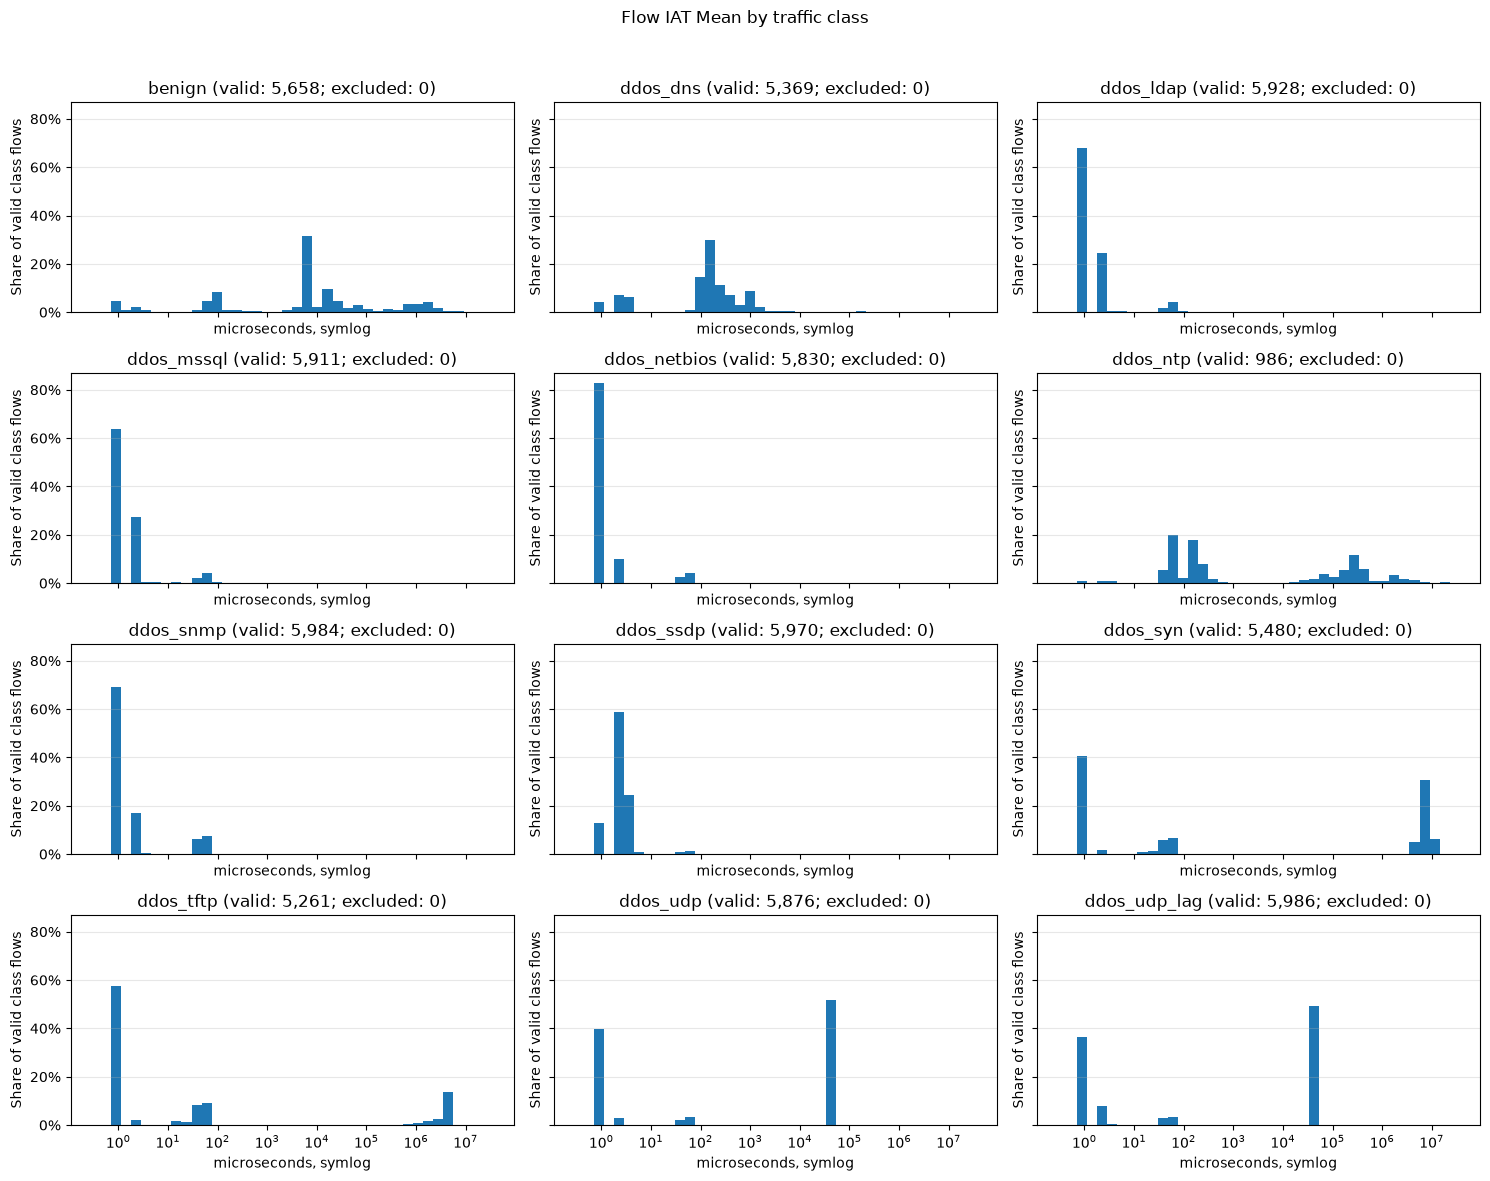

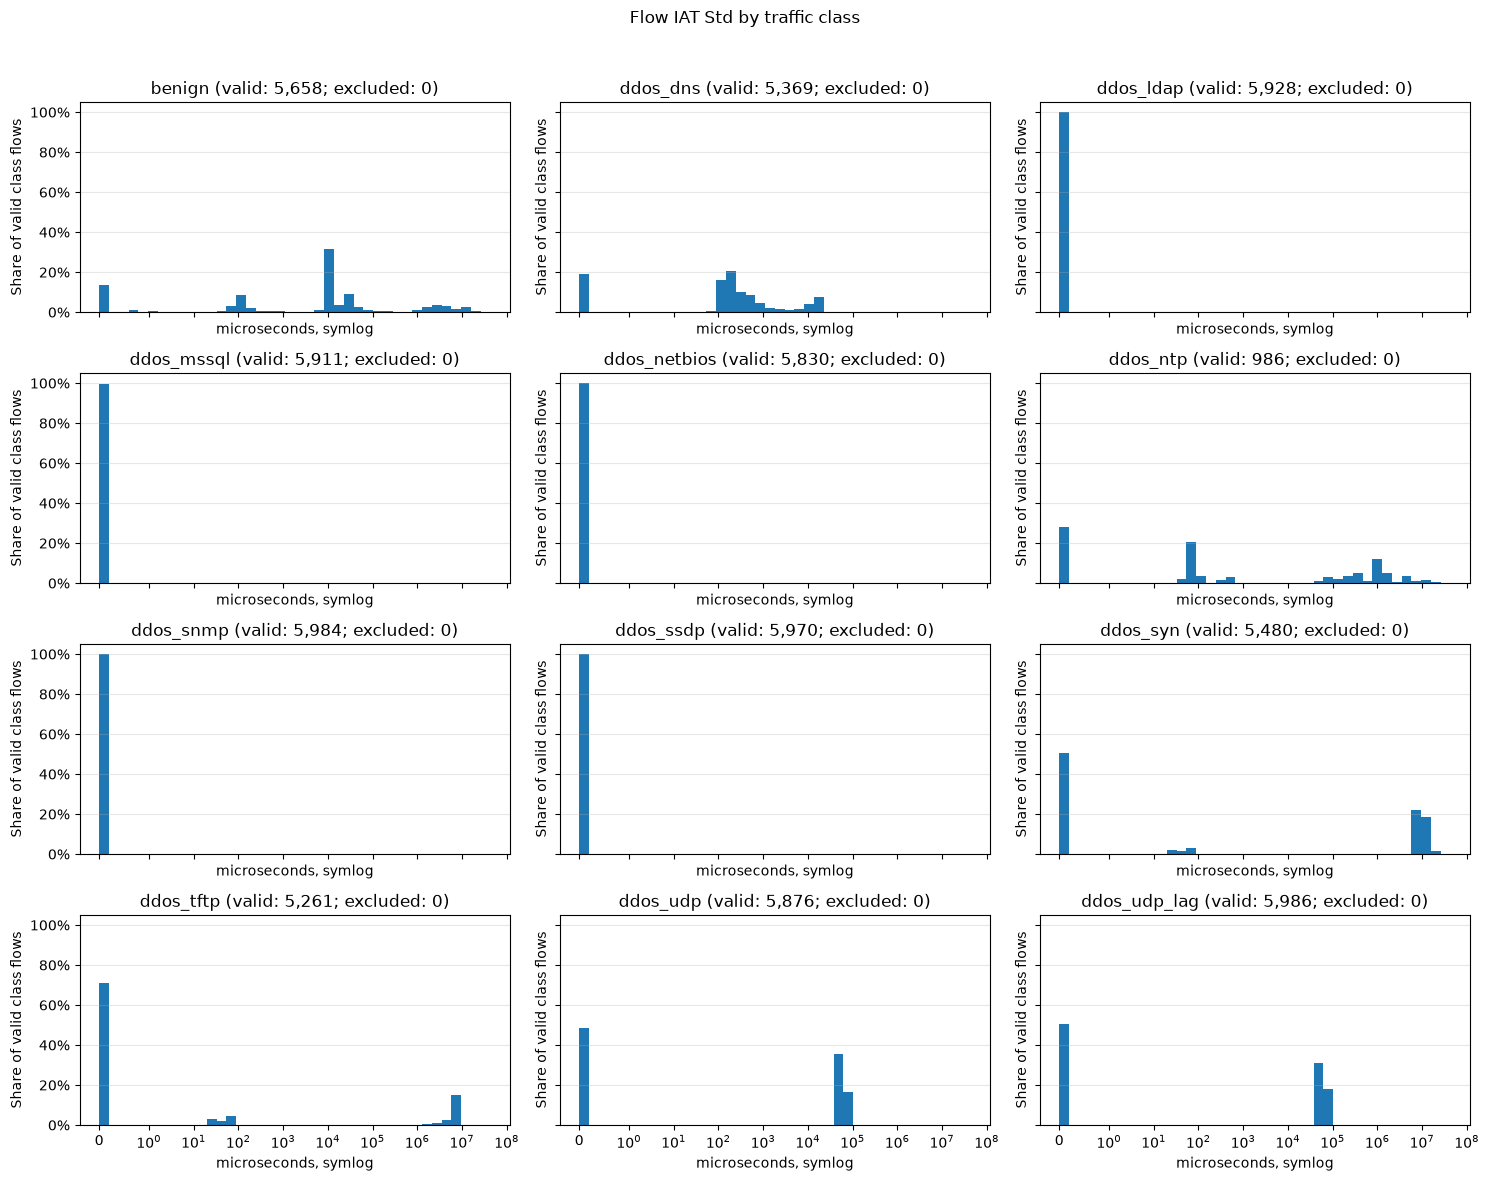

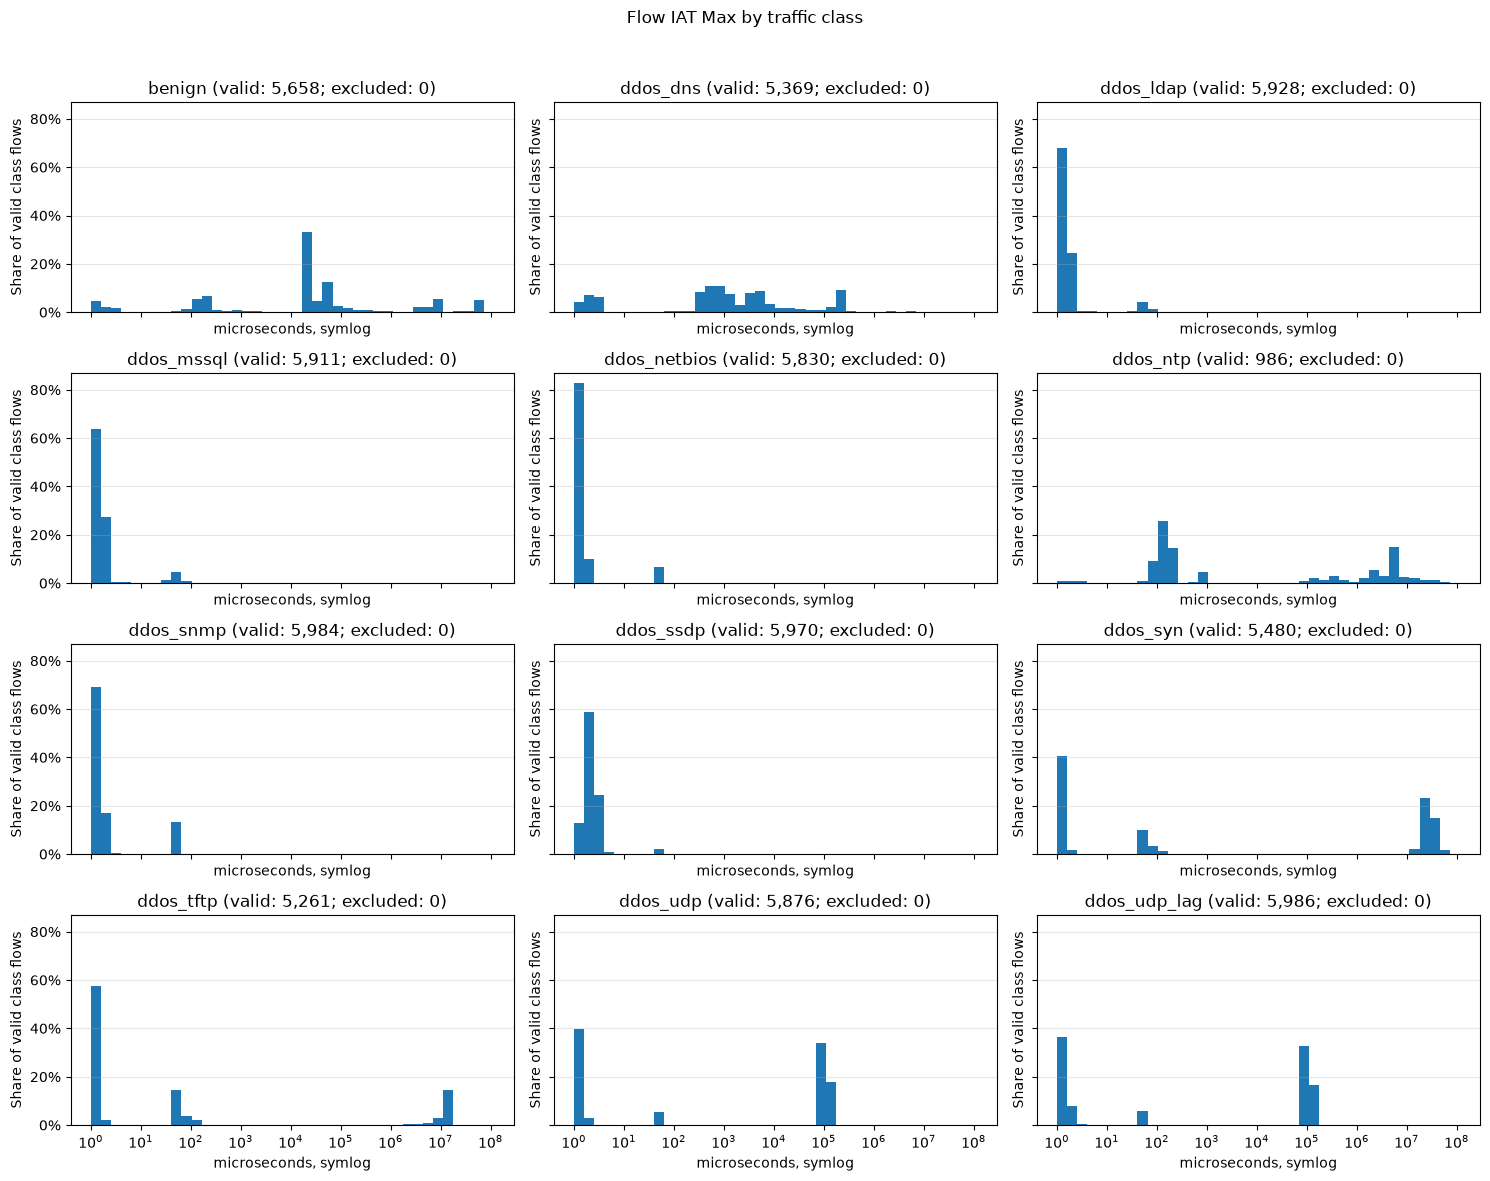

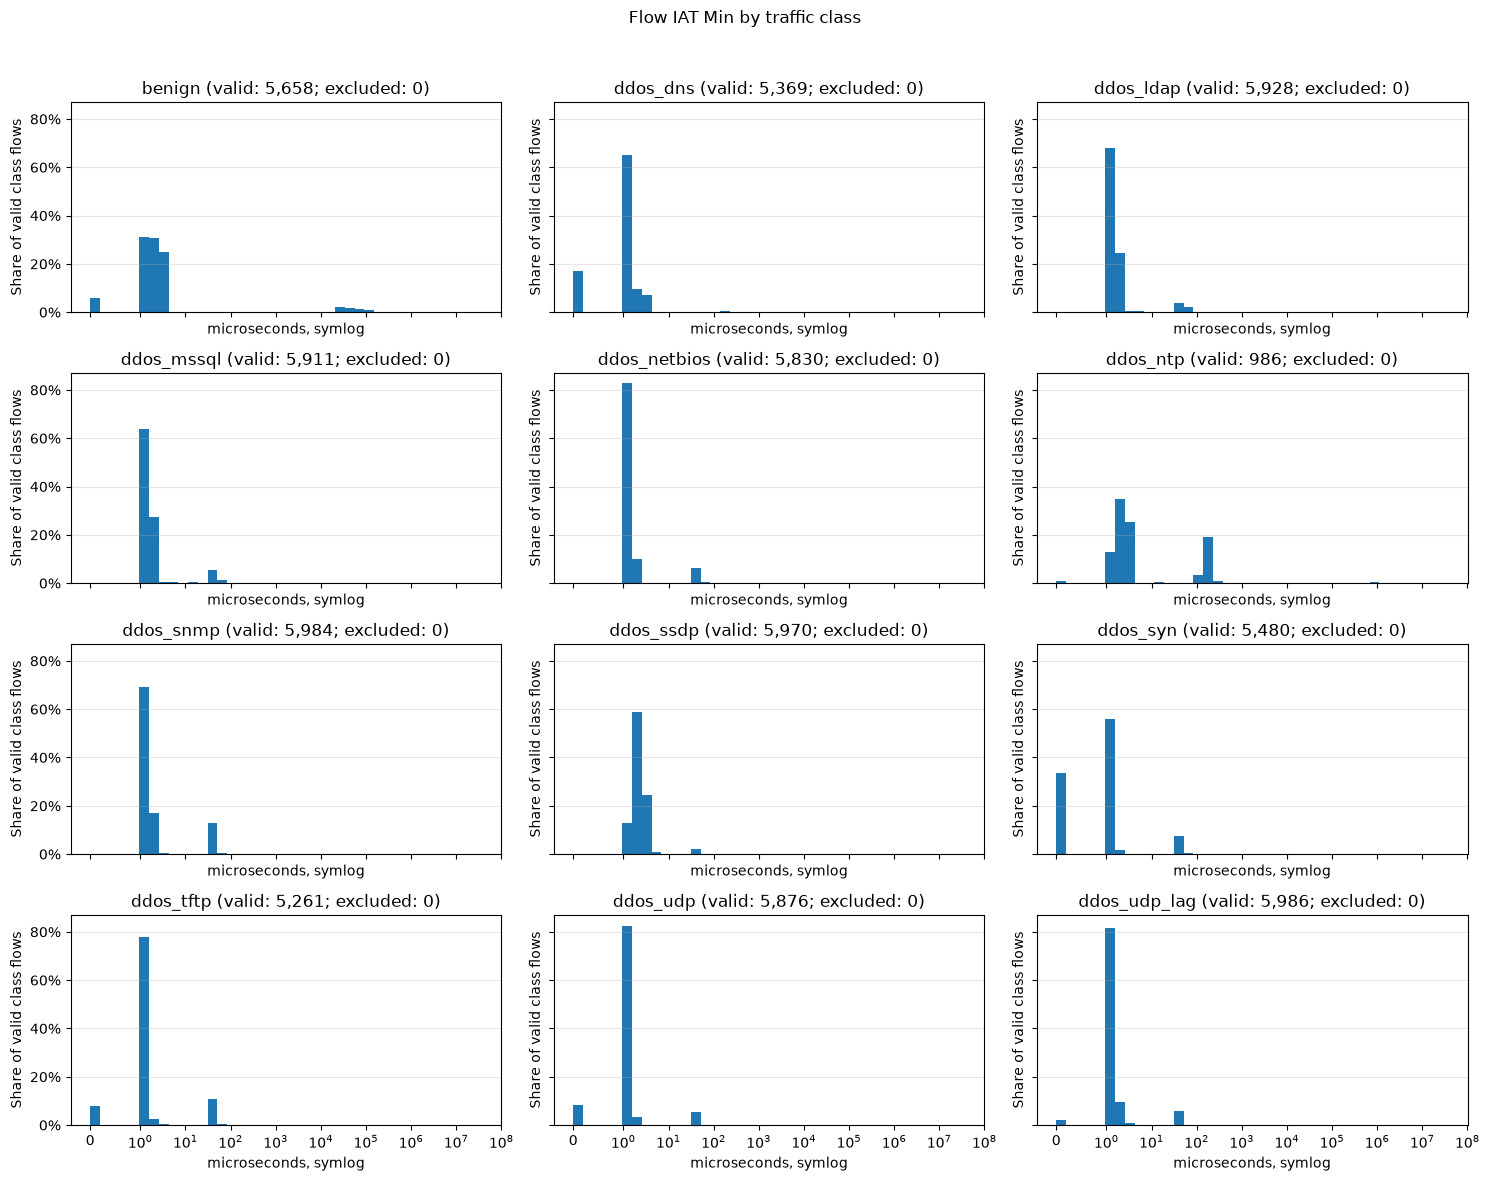

In [7]:
exploration.plot_flow_iat_histograms(df_timing)

### Forward versus backward IAT

Compare matching Total, Mean, Std, Max, and Min IAT summaries. Each point is one flow; colors identify traffic classes and stay consistent across panels. The dashed diagonal means equal forward and backward values. For example, a point above the diagonal in the Mean panel has a larger mean gap between backward packets than forward packets.

Both axes use microseconds and symmetric log scales, linear between -1 and 1. Equal axis limits within each panel support directional comparison while keeping zeros visible. Small transparent points reduce overlap; a fixed random drawing order prevents one class from always appearing on top. All finite pairs are plotted, with no sampling. Missing or infinite values are excluded separately for each pair and counted in the panel title. Zero values are retained as recorded and do not by themselves prove a measured zero gap. Plotting does not change `df_timing`.


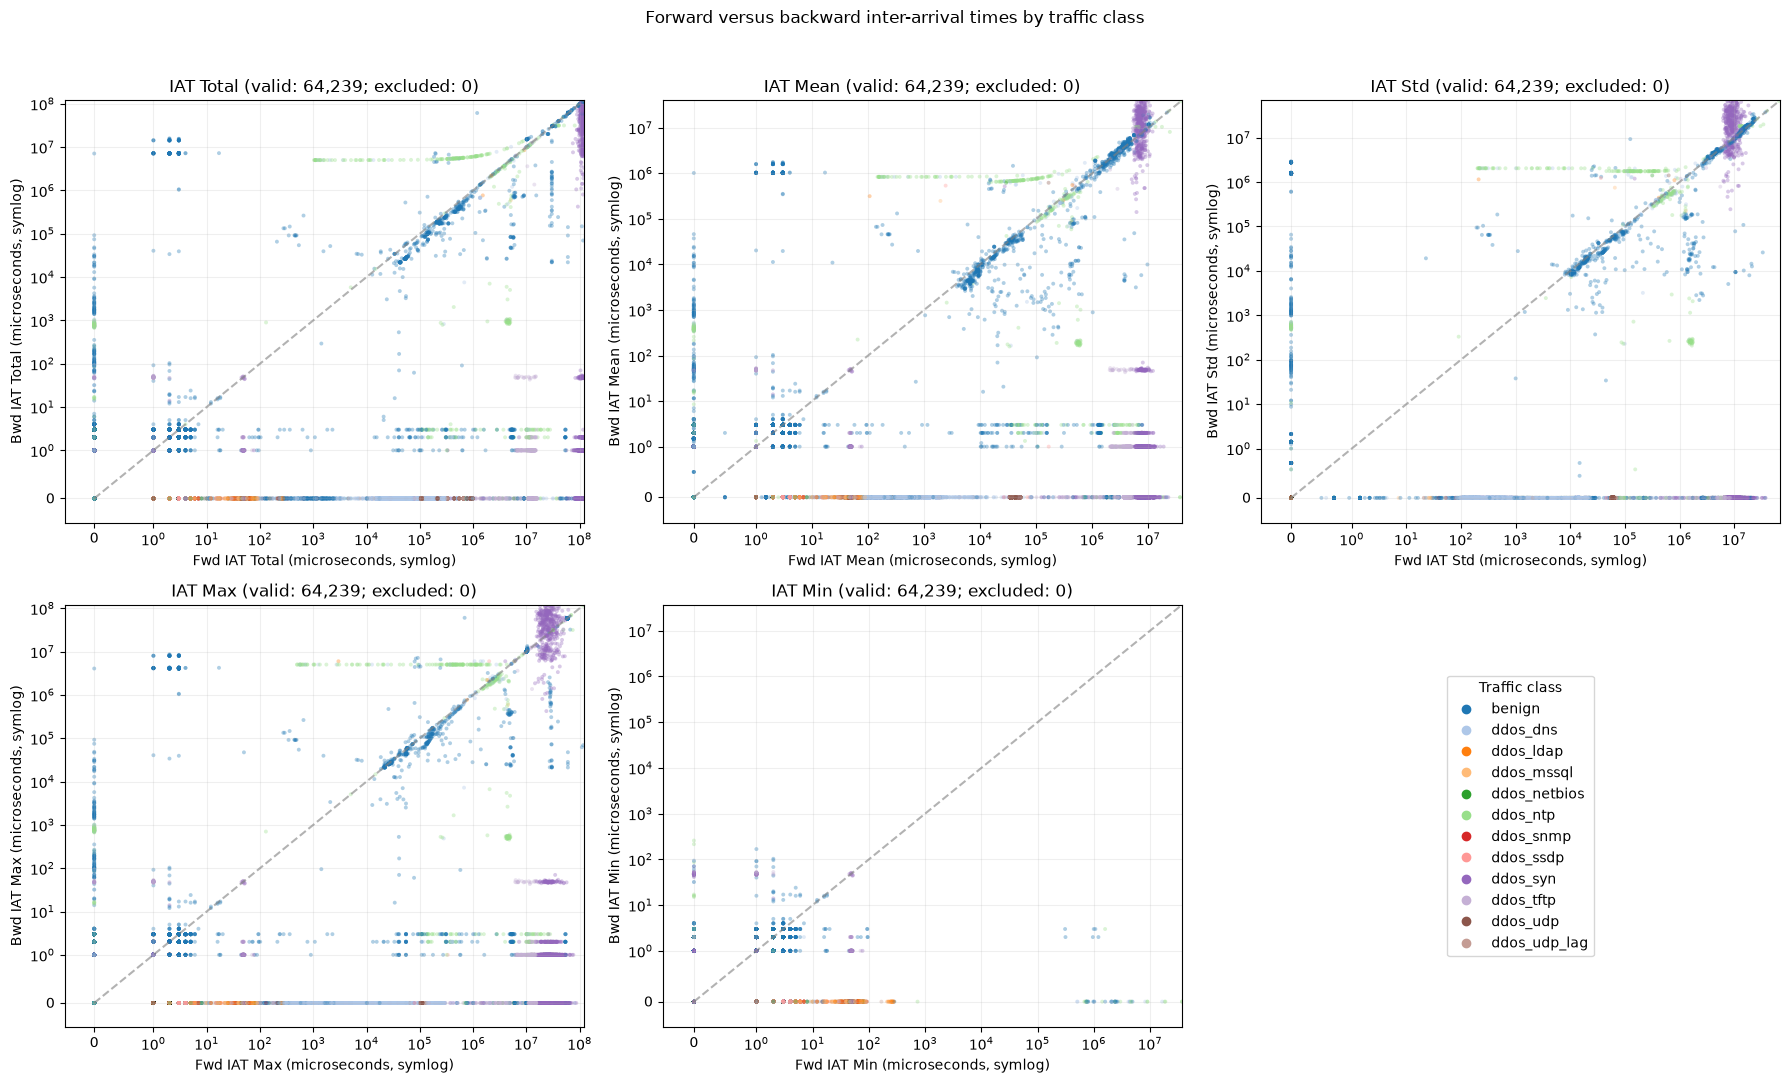

In [8]:
exploration.plot_directional_iat_scatter(df_timing)

### Forward/backward IAT correlation matrix

Compute correlations among all ten directional IAT features: Total, Mean, Std, Max, and Min in each direction. The heatmap uses signed Spearman correlations, which compare ranks and capture monotonic relationships without requiring a straight-line relationship. Pearson correlation is an alternative for linear relationships; use `method="pearson"` to compare.

Values near +1 indicate that the two features tend to increase together; values near -1 indicate opposite ordering. Values near 0 indicate little monotonic association. For example, a strong positive correlation between `Fwd IAT Mean` and `Bwd IAT Mean` means flows with larger forward gaps tend to have larger backward gaps. This does not establish causation or how well either feature separates classes.

The matrix pools all traffic classes, so class differences can influence the correlations. Missing and infinite values are excluded separately for each pair; pairs can therefore use different numbers of flows. Gray cells marked N/A indicate undefined correlations, such as a constant feature or too few valid observations. The dataframe is unchanged, and the returned matrix is saved as `iat_correlations`.


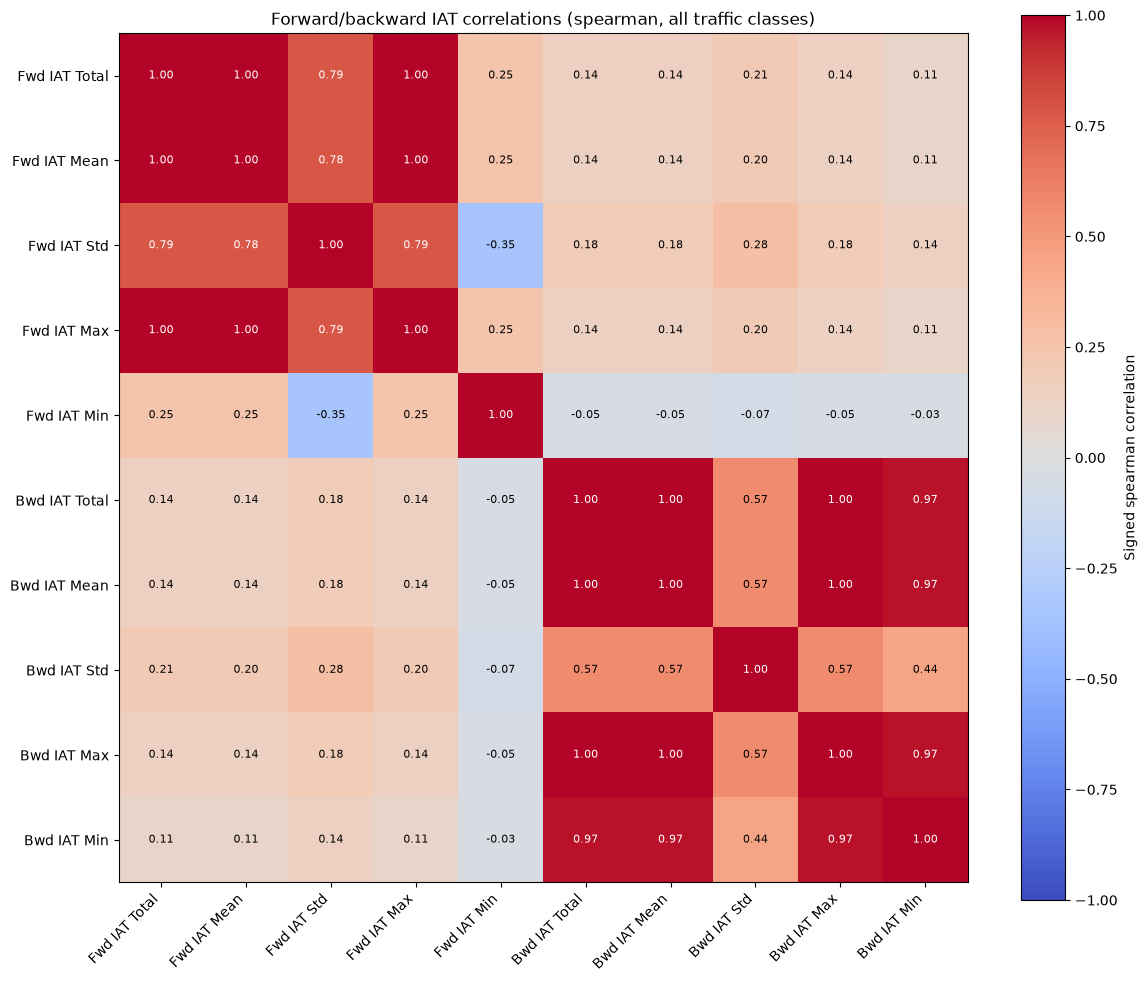

In [9]:
iat_correlations = exploration.plot_directional_iat_correlations(df_timing)

### Remove highly correlated IAT features

Use the heatmap matrix to remove directional IAT features with absolute Spearman correlation at least 0.90. Absolute values count strong negative relationships as well as positive ones. Check Mean columns first so they take priority; if two Mean columns exceed the cutoff, keep the first in matrix order. Within each priority group, keep the original matrix order for reproducible choices.

Compare each candidate only with features already retained. For example, if `Fwd IAT Max` correlates strongly with the retained `Fwd IAT Mean`, remove Max and record Mean as the reason. This greedy approach is simple and explainable, but the order can affect which features survive; it does not search for the smallest possible feature set. Undefined correlations do not justify removing a column.

`df_timing_reduced` keeps all rows, ports, labels, and timing features outside the ten-column heatmap. It is a copy, so the original `df_timing` remains available for the plots below. The report records each removed feature, its retained counterpart, and their signed correlation. Correlation measures overlap, not whether a feature helps distinguish attack classes. For later model evaluation, choose features using training data only to keep test data out of the selection process.


In [12]:
correlation_cutoff = 0.90
df_timing_reduced, removed_iat_features = exploration.reduce_correlated_features(
    df_timing, iat_correlations, cutoff=correlation_cutoff
)
print(f"Columns: {df_timing.shape[1]} -> {df_timing_reduced.shape[1]}")
print(f"Rows retained: {len(df_timing_reduced):,}")
removed_iat_features


Columns: 22 -> 17
Rows retained: 64,239


,Removed,Retained,Correlation
0,Fwd IAT Total,Fwd IAT Mean,0.998426
1,Fwd IAT Max,Fwd IAT Mean,0.998811
2,Bwd IAT Total,Bwd IAT Mean,0.999924
3,Bwd IAT Max,Bwd IAT Mean,0.999974
4,Bwd IAT Min,Bwd IAT Mean,0.972053


### Focus on directional IAT mean and standard deviation

Use Mean and Std in each direction for this reduced comparison after inspecting the correlation matrix. Mean describes the typical packet gap, while Std describes how much the gaps vary. Correlation suggests overlap between measurements, but does not establish that the omitted summaries have no value for distinguishing attacks. Keep the full feature set available for the assigned analysis.

The two panels compare forward versus backward Mean and forward versus backward Std, using the same class colors and symmetric log axes as before. For example, a point above the diagonal in the Std panel has more variable backward packet gaps than forward gaps.


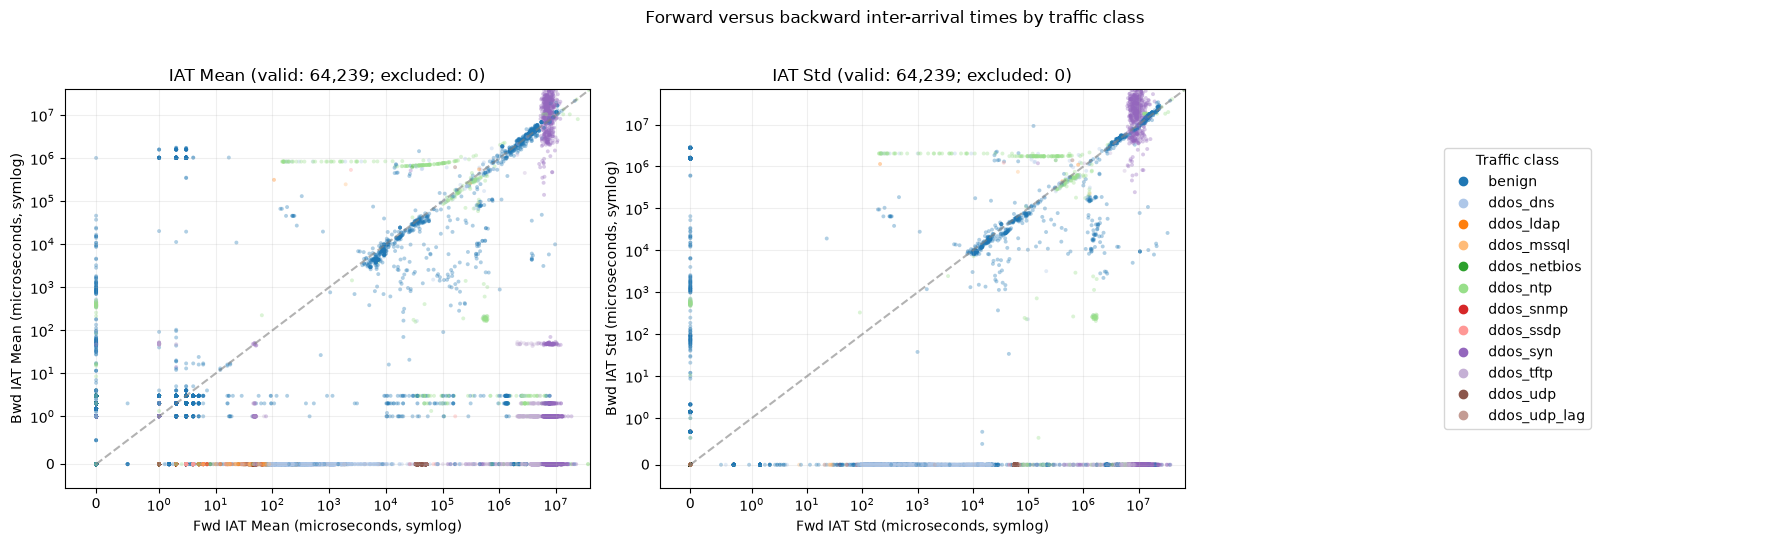

In [14]:
exploration.plot_directional_iat_scatter(df_timing_reduced, summaries=("Mean", "Std"))

### Directional bytes and packets per second

Plot forward versus backward bytes/s and packets/s in separate figures, with consistent colors for traffic classes. Packet rates are already recorded. Directional byte rates are derived as total bytes in each direction divided by flow duration in seconds; durations are stored in microseconds, so divide duration by 1,000,000 first. For example, 1,000 forward bytes in 0.5 seconds gives 2,000 forward bytes/s. Use `df_stripped` because it still contains the directional byte totals needed for this calculation.

Both axes use symmetric log scales, linear between -1 and 1, to keep zeros visible. The dashed diagonal indicates equal rates. Points above it have higher backward rates. Small transparent points and a fixed random drawing order reduce overlap while preserving all finite pairs. Byte rates with missing, infinite, or nonpositive durations are undefined and excluded. Recorded packet rates are filtered independently for finite values. Each figure reports excluded pairs. Calculations use a copy and preserve the original data; `directional_rates` retains the derived rates for later inspection.


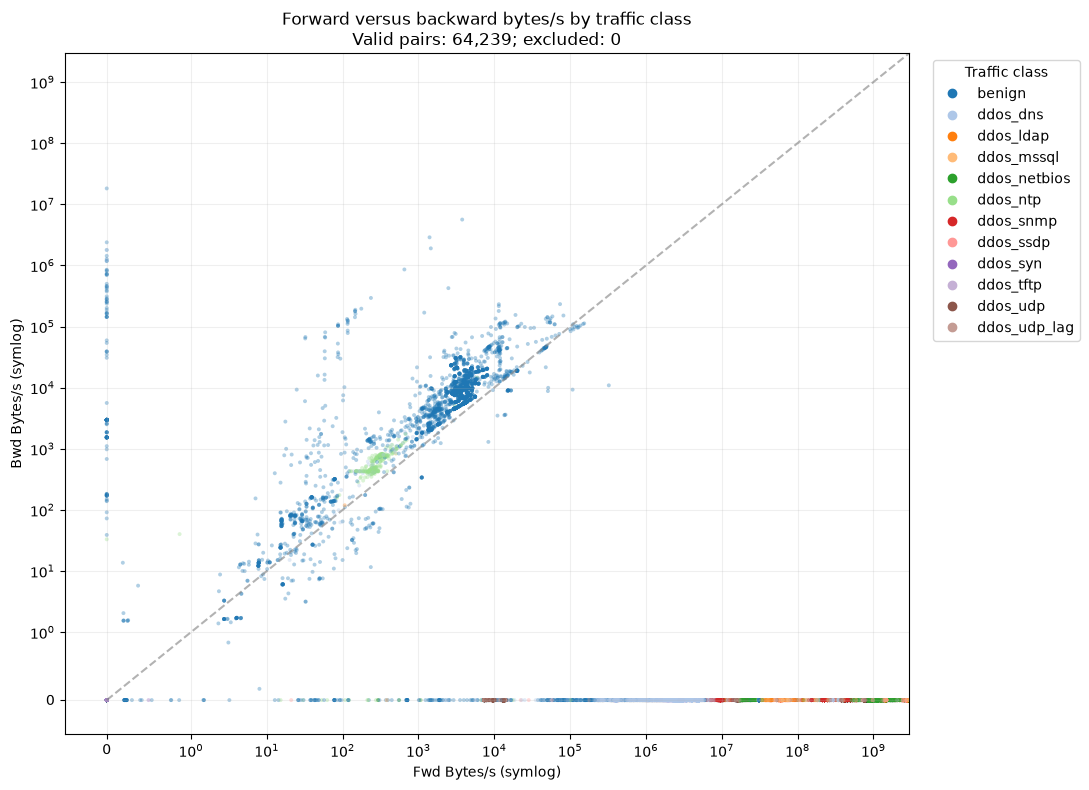

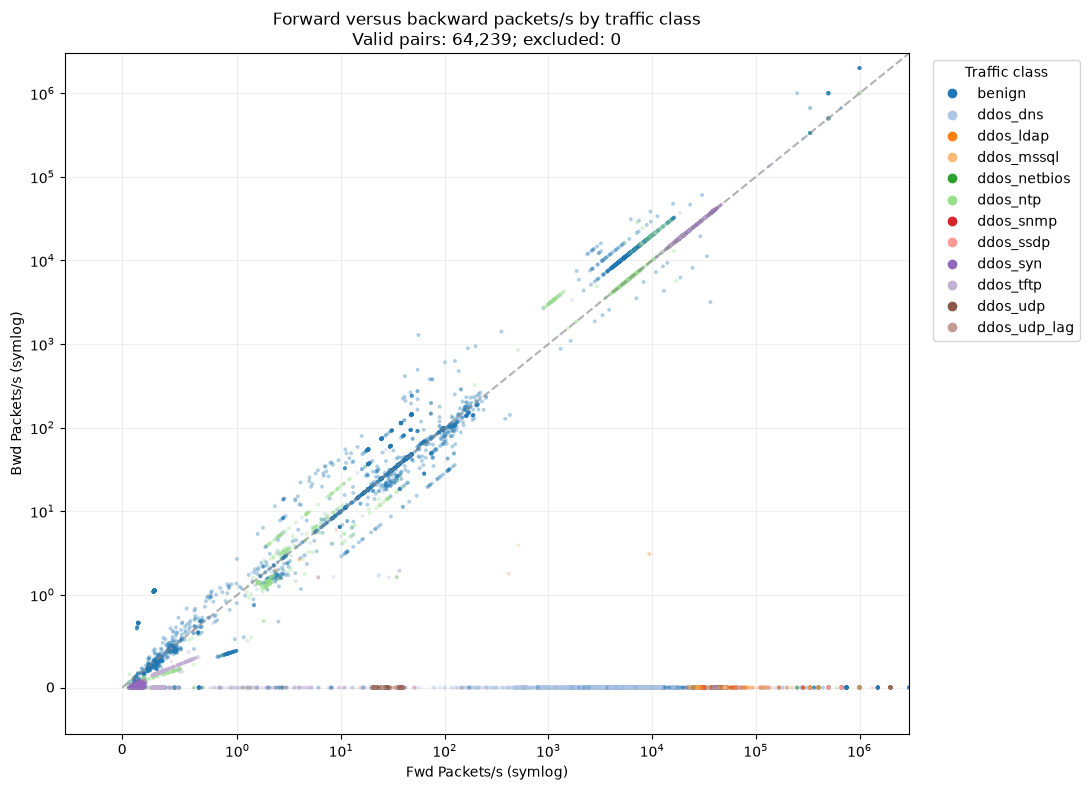

In [11]:
directional_rates = exploration.plot_directional_rate_scatter(df_stripped)

### Backward packets per second by traffic class

Compare `Bwd Packets/s` across traffic classes using one horizontal boxplot per class. Each box spans the 25th to 75th percentiles, and its black line marks the median. Whiskers reach the most extreme observed values within 1.5 times the box width beyond each end; points outside them are shown individually. These points are unusual relative to their class, not necessarily errors. For example, a class with a higher median has a higher typical backward packet rate.

Use a symmetric log x-axis to keep long tails readable while retaining zeros. It is linear between -1 and 1 and logarithmic outside that range. Quartiles and whiskers are calculated on the original rates before scaling the axis. Missing and infinite rates are excluded and counted beside each class; the displayed axis starts at -1, so rates below -10⁰ are outside the view but still contribute to the boxplot statistics. Classes without finite rates have no visible box. The input dataframe is unchanged.


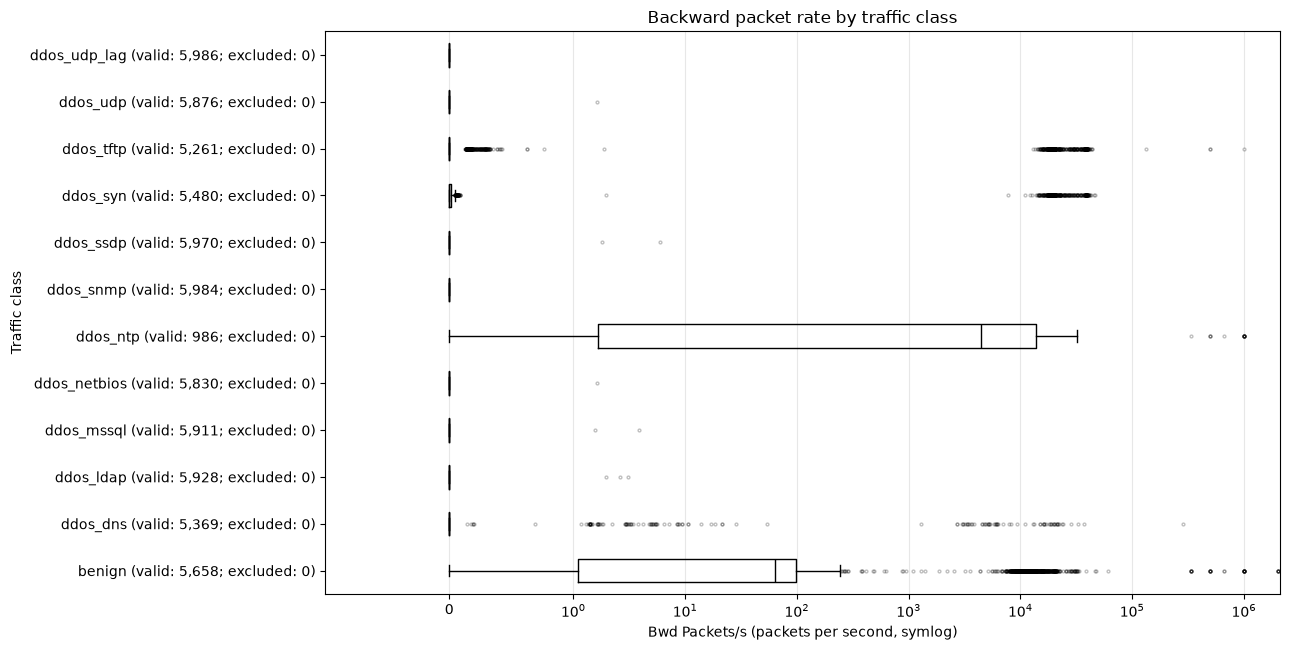

In [17]:
exploration.plot_backward_packet_rate_boxplots(df_timing_reduced)